In [1]:
import os

os.listdir()

['Phishing_Classification.ipynb']

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("phishing_dataset.csv")

df.head()

,id,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [3]:
df.shape

(11055, 32)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   id                           11055 non-null  int64
 1   having_IP_Address            11055 non-null  int64
 2   URL_Length                   11055 non-null  int64
 3   Shortining_Service           11055 non-null  int64
 4   having_At_Symbol             11055 non-null  int64
 5   double_slash_redirecting     11055 non-null  int64
 6   Prefix_Suffix                11055 non-null  int64
 7   having_Sub_Domain            11055 non-null  int64
 8   SSLfinal_State               11055 non-null  int64
 9   Domain_registeration_length  11055 non-null  int64
 10  Favicon                      11055 non-null  int64
 11  port                         11055 non-null  int64
 12  HTTPS_token                  11055 non-null  int64
 13  Request_URL                  11055 non-null  int64
 14  U

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
print(df["Result"].value_counts())

Duplicate rows: 0

Target distribution:
Result
 1    6157
-1    4898
Name: count, dtype: int64


In [6]:
df["Result"].value_counts(normalize=True) * 100

Result
 1    55.694256
-1    44.305744
Name: proportion, dtype: float64

In [7]:
# Remove the identifier column
X = df.drop(columns=["id", "Result"])

# Convert target:
# -1 = phishing → 0
#  1 = legitimate → 1
y = df["Result"].map({-1: 0, 1: 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

Feature shape: (11055, 30)
Target shape: (11055,)

Target values:
Result
1    6157
0    4898
Name: count, dtype: int64


removes id because it is not useful for prediction
separates the input features into X
separates the answer column Result into y
changes labels from -1 and 1 into 0 and 1
prints the dataset sizes and class counts

In [8]:
skewness = X.skew().sort_values(ascending=False)

skewness

Redirect                       2.403304
Prefix_Suffix                  2.167975
URL_Length                     1.636149
SFH                            1.476049
Page_Rank                      1.105373
Domain_registeration_length    0.715423
Links_in_tags                  0.202672
URL_of_Anchor                  0.113016
having_Sub_Domain             -0.118125
age_of_domain                 -0.122725
Links_pointing_to_page        -0.172408
Request_URL                   -0.380331
SSLfinal_State                -0.515502
web_traffic                   -0.576535
having_IP_Address             -0.661064
DNSRecord                     -0.814466
popUpWidnow                   -1.553519
Favicon                       -1.616655
Submitting_to_email           -1.646990
HTTPS_token                   -1.830363
having_At_Symbol              -1.963891
Abnormal_URL                  -1.990042
Statistical_report            -2.072799
Google_Index                  -2.084740
port                          -2.125709


In [9]:
skewness.describe()

count    30.000000
mean     -0.817310
std       1.603748
min      -4.502809
25%      -2.052110
50%      -0.737765
75%       0.055231
max       2.403304
dtype: float64

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (8844, 30)
Testing features: (2211, 30)
Training target: (8844,)
Testing target: (2211,)


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (8844, 30)
Scaled testing shape: (2211, 30)


In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Model training completed")

Model training completed


In [13]:
y_pred = model.predict(X_test_scaled)

print("Predictions generated")
print(y_pred[:10])

Predictions generated
[0 0 1 0 0 1 1 1 1 1]


In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9285391225689733
Precision: 0.9234411996842936
Recall: 0.950446791226645
F1-score: 0.9367493995196157

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.90      0.92       980
           1       0.92      0.95      0.94      1231

    accuracy                           0.93      2211
   macro avg       0.93      0.93      0.93      2211
weighted avg       0.93      0.93      0.93      2211



your model is working, but the F1-score is 0.9367, which is below the assignment’s target of 0.98. We should improve it carefully rather than changing everything randomly.

[[ 883   97]
 [  61 1170]]


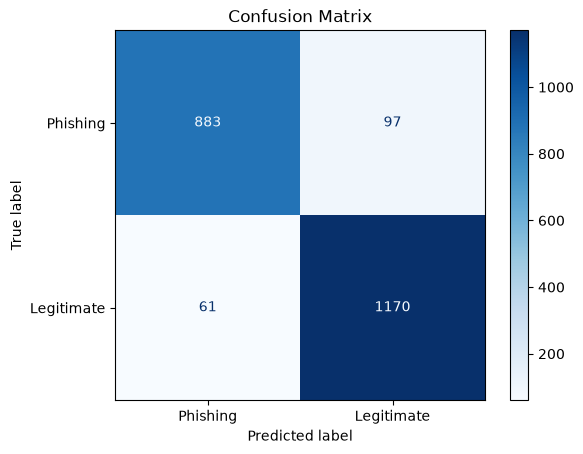

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Phishing", "Legitimate"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

The confusion matrix shows:
correctly detected phishing websites
phishing websites incorrectly classified as legitimate
correctly detected legitimate websites
legitimate websites incorrectly classified as phishing

The model correctly classified:
883 phishing websites
1,170 legitimate websites

It made 158 total mistakes.

The next step is threshold tuning, which may improve the F1-score. Instead of automatically using the default probability threshold of 0.5, we’ll test different thresholds and select one based on the F1-score.


Best threshold: 0.44999999999999984
Best F1-score: 0.9383207321925985


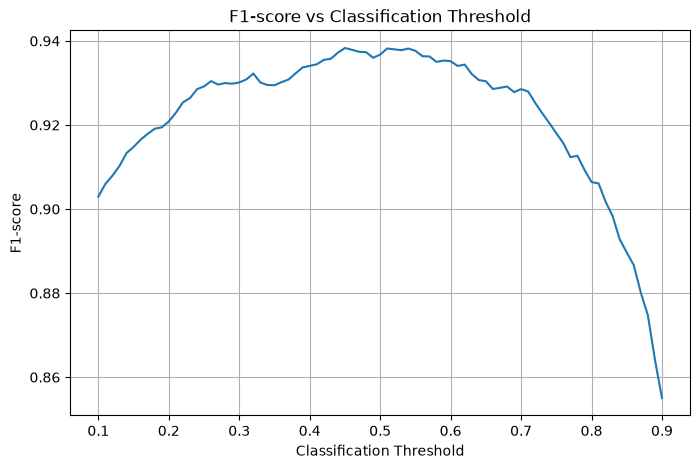

In [16]:
from sklearn.metrics import f1_score
import numpy as np
import matplotlib.pyplot as plt

# Get probability of class 1 (legitimate)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

thresholds = np.arange(0.1, 0.91, 0.01)
f1_scores = []

for threshold in thresholds:
    y_threshold_pred = (y_prob >= threshold).astype(int)
    score = f1_score(y_test, y_threshold_pred)
    f1_scores.append(score)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print("Best threshold:", best_threshold)
print("Best F1-score:", best_f1)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores)
plt.xlabel("Classification Threshold")
plt.ylabel("F1-score")
plt.title("F1-score vs Classification Threshold")
plt.grid(True)
plt.show()

## Explanation of the Code

### 1. Import the required libraries

Python

Run

```
from sklearn.metrics import f1_score
import numpy as np
import matplotlib.pyplot as plt
```

* `f1_score` calculates the F1-score of the model.

* `numpy` is used to create the threshold values.

* `matplotlib.pyplot` is used to plot the graph.

### 2. Get prediction probabilities

Python

Run

```
y_prob = model.predict_proba(X_test_scaled)[:, 1]
```

`predict_proba()` returns the probability of each class for every test sample.

The expression `[:, 1]` selects the probability of class `1`, which represents a legitimate website.

For example:

* `0.20` means a 20% probability of being legitimate.

* `0.75` means a 75% probability of being legitimate.

### 3. Create a range of thresholds

Python

Run

```
thresholds = np.arange(0.1, 0.91, 0.01)
```

This creates threshold values from `0.10` to `0.90`, increasing by `0.01`.

The model will be tested using each of these thresholds instead of using only the default threshold of `0.50`.

### 4. Create an empty list for F1-scores

Python

Run

```
f1_scores = []
```

This list stores the F1-score calculated for each threshold.

### 5. Test each threshold

Python

Run

```
for threshold in thresholds:
    y_threshold_pred = (y_prob >= threshold).astype(int)
    score = f1_score(y_test, y_threshold_pred)
    f1_scores.append(score)
```

For every threshold:

1. The model probabilities are compared with the current threshold.

2. If the probability is greater than or equal to the threshold, the prediction is `1`.

3. Otherwise, the prediction is `0`.

4. The F1-score is calculated using the actual labels and predicted labels.

5. The F1-score is added to the list.

For example, with a threshold of `0.45`:

* Probability `0.70` → prediction `1`

* Probability `0.30` → prediction `0`

### 6. Find the best threshold

Python

Run

```
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]
```

* `np.argmax(f1_scores)` finds the position of the highest F1-score.

* `best_threshold` stores the threshold that produced the highest score.

* `best_f1` stores the highest F1-score.

In this experiment:

```
Best threshold: approximately 0.45
Best F1-score: 0.9383
```

### 7. Display the best results

Python

Run

```
print("Best threshold:", best_threshold)
print("Best F1-score:", best_f1)
```

This prints the threshold and F1-score that performed best.

### 8. Plot the results

Python

Run

```
plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores)
plt.xlabel("Classification Threshold")
plt.ylabel("F1-score")
plt.title("F1-score vs Classification Threshold")
plt.grid(True)
plt.show()
```

This creates a graph showing how the F1-score changes for different classification thresholds.

### Overall purpose

The code tests multiple classification thresholds and selects the threshold that produces the highest F1-score.


In [17]:
# Apply the tuned threshold
y_tuned_pred = (y_prob >= best_threshold).astype(int)

# Calculate tuned metrics
tuned_accuracy = accuracy_score(y_test, y_tuned_pred)
tuned_precision = precision_score(y_test, y_tuned_pred)
tuned_recall = recall_score(y_test, y_tuned_pred)
tuned_f1 = f1_score(y_test, y_tuned_pred)

print("Tuned Accuracy:", tuned_accuracy)
print("Tuned Precision:", tuned_precision)
print("Tuned Recall:", tuned_recall)
print("Tuned F1-score:", tuned_f1)

print("\nTuned Classification Report:")
print(classification_report(y_test, y_tuned_pred))

Tuned Accuracy: 0.9298959746720941
Tuned Precision: 0.9196567862714509
Tuned Recall: 0.9577579203899269
Tuned F1-score: 0.9383207321925985

Tuned Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.89      0.92       980
           1       0.92      0.96      0.94      1231

    accuracy                           0.93      2211
   macro avg       0.93      0.93      0.93      2211
weighted avg       0.93      0.93      0.93      2211



Precision measures how many of the websites predicted as class 1 were actually class 1.

Accuracy measures the overall percentage of correct predictions.
Accuracy=Total Predictions/Correct Predictions

Recall measures how many actual class 1 websites were correctly identified.
A higher threshold may reduce recall, while a lower threshold may increase recall.

The F1-score is the harmonic mean of precision and recall.

F1=2×(Precision+Recall)/(Precision×Recall)


In [18]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "Best Threshold"],
    "Value": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        best_threshold
    ]
})

results

,Metric,Value
0,Accuracy,0.929896
1,Precision,0.919657
2,Recall,0.957758
3,F1-score,0.938321
4,Best Threshold,0.450000


In [19]:
results.to_csv("phishing_model_results.csv", index=False)